**Project Overview**

For my final project, I chose the first research option outlined in the course guidelines. My research question is: Are LLMs sensitive to world knowledge violations?
To investigate this, I will test whether a Large Language Model (GPT-2) shows higher surprisal for sentences that end with a word that violates common-sense world knowledge compared to sentences that end with a plausible word. This approach is inspired by classic psycholinguistic experiments that measure how humans process expected vs. unexpected information.


**1. Design of Stimulus**

I made ten "minimal pairs" of stimuli to test my research question. A plausible word (the "Plausible" condition) or a word that deviates from world knowledge (the "Violation" condition) completes the sentence context in each pair. This yields 20 distinct stimuli items in total.

By changing only the last word and maintaining the same sentence context within each pair, I attempted to account for any potential confounds.
The stimuli I created are as follows:

In [ ]:
import pandas as pd

In [ ]:
### Final Project Stimuli
stimuli = [
    # Pair 1
    ('To unlock the door, he used a', ' key', 'Plausible'),
    ('To unlock the door, he used a', ' banana', 'Violation'),
    # Pair 2
    ('In the winter, water turns to', ' ice', 'Plausible'),
    ('In the winter, water turns to', ' fire', 'Violation'),
    # Pair 3
    ('Birds build their nests in', ' trees', 'Plausible'),
    ('Birds build their nests in', ' oceans', 'Violation'),
    # Pair 4
    ('Most dogs have four', ' legs', 'Plausible'),
    ('Most dogs have four', ' wheels', 'Violation'),
    # Pair 5
    ('You can read words in a', ' book', 'Plausible'),
    ('You can read words in a', ' rock', 'Violation'),
    # Pair 6
    ('A chef cooks food in a', ' kitchen', 'Plausible'),
    ('A chef cooks food in a', ' library', 'Violation'),
    # Pair 7
    ('To see in the dark, you use a', ' light', 'Plausible'),
    ('To see in the dark, you use a', ' chair', 'Violation'),
    # Pair 8
    ('The sun is very', ' hot', 'Plausible'),
    ('The sun is very', ' cold', 'Violation'),
    # Pair 9
    ('Fish can breathe in', ' water', 'Plausible'),
    ('Fish can breathe in', ' air', 'Violation'),
    # Pair 10
    ('The opposite of black is', ' white', 'Plausible'),
    ('The opposite of black is', ' loud', 'Violation')
]

# Create DataFrame
df_stimuli = pd.DataFrame(stimuli, columns = ['Sentence', 'Word', 'Condition'])
df_stimuli.head(4)

,Sentence,Word,Condition
0,"To unlock the door, he used a",key,Plausible
1,"To unlock the door, he used a",banana,Violation
2,"In the winter, water turns to",ice,Plausible
3,"In the winter, water turns to",fire,Violation


**2. Discussion of Potential Confounds**

While designing these stimuli, I considered a few potential confounds:
Word Frequency: The "violation" words might be less frequent in general than the "plausible" words. For example, legs is likely more common than wheels following the phrase "four...". The model's surprisal might reflect this co-occurrence frequency rather than a true "understanding" of world knowledge. My design attempts to mitigate this where possible, but it's a difficult confound to eliminate completely without normative data.

Metaphorical Usage: Some violations could, in a metaphorical or fictional context, be plausible (e.g., "the sun is cold" in a poem). The model may have been trained on such text, which could reduce the surprisal for some "violation" items.

Model Limitations: I am using GPT-2, which is a relatively older and smaller model. Its representation of "world knowledge" may be less robust or accurate than that of newer, larger models. Therefore, these findings might not generalize to the capabilities of state-of-the-art LLMs.

**3. Method: Calculating Surprisal**

I will use the next_seq_prob and surprisal functions defined in the lab to calculate the surprisal of the final word for each of my 20 stimuli. The code below iterates through my df_stimuli DataFrame, calculates the probability and surprisal for each sentence-word pair, and stores the results.

In [ ]:
import torch
import transformers
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
gpt2 = transformers.AutoModelForCausalLM.from_pretrained("gpt2")  # Load the model
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")

def next_seq_prob(model, tokenizer, seen, unseen):
    """Get p(unseen | seen)

    Parameters
    ----------
    model : transformers.PreTrainedModel
        Model to use for predicting tokens
    tokenizer : transformers.PreTrainedTokenizer
        Tokenizer for Model
    seen : str
        Input sequence
    unseen: str
        The sequence for which to calculate a probability
    """
    # Get ids for tokens
    input_ids = tokenizer.encode(seen, return_tensors="pt")
    unseen_ids = tokenizer.encode(unseen)

    # Loop through unseen tokens & store log probs
    log_probs = []
    for unseen_id in unseen_ids:

        # Run model on input
        with torch.no_grad():
            logits = model(input_ids).logits

        # Get next token prediction logits
        next_token_logits = logits[0, -1]
        next_token_probs = torch.softmax(next_token_logits, 0) # Normalize

        # Get probability for relevant token in unseen string & store
        prob = next_token_probs[unseen_id]
        log_probs.append(torch.log(prob))

        # Add input tokens incrementally to input
        input_ids = torch.cat((input_ids, torch.tensor([[unseen_id]])), 1)

    # Add log probs together to get total log probability of sequence
    total_log_prob = sum(log_probs)
    # Exponentiate to return to probabilities
    total_prob = torch.exp(total_log_prob)
    return total_prob.item()

def surprisal(p):
   return -np.log2(p)

In [ ]:
# Calculate probabilities and surprisal
results = []
for index, row in tqdm(df_stimuli.iterrows(), total=df_stimuli.shape[0], desc="Processing Project Stimuli"):
    prob = next_seq_prob(gpt2, tokenizer, row['Sentence'], row['Word'])

    # Handle cases where probability is zero to avoid log(0) errors
    if prob == 0.0:
        current_surprisal = float('inf')
    else:
        current_surprisal = surprisal(prob)

    results.append({
        'Word': row['Word'],
        'Sentence': row['Sentence'],
        'Condition': row['Condition'],
        'Probability': prob,
        'Surprisal': current_surprisal
    })

# Create DataFrame from results
df_results = pd.DataFrame(results)
df_results.head(4)

Processing Project Stimuli: 100%|██████████| 20/20 [00:06<00:00,  3.10it/s]


,Word,Sentence,Condition,Probability,Surprisal
0,key,"To unlock the door, he used a",Plausible,0.011608,6.428682
1,banana,"To unlock the door, he used a",Violation,0.000186,12.393018
2,ice,"In the winter, water turns to",Plausible,0.246329,2.021342
3,fire,"In the winter, water turns to",Violation,0.004195,7.896974


**4. Results and Visualization**

After calculating the surprisal for all 20 items, I will visualize the results. The key prediction is that the average surprisal for the "Violation" condition should be significantly higher than for the "Plausible" condition. I will use a bar plot to compare the means of the two conditions.


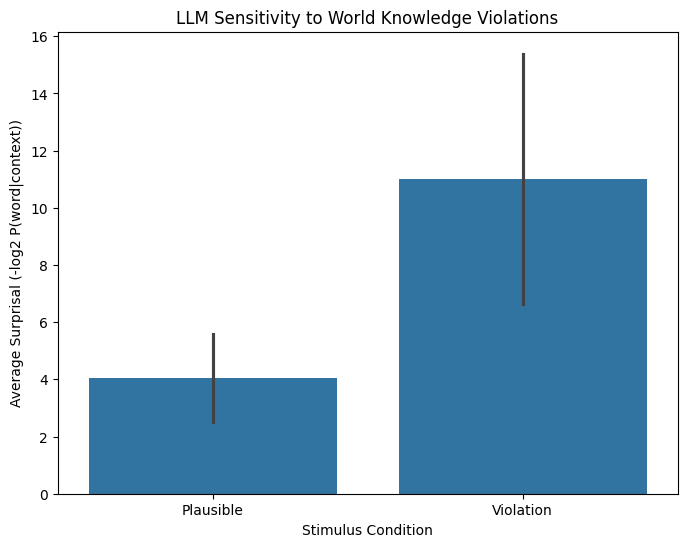

In [ ]:
# Now visualize results!
plt.figure(figsize=(8, 6))
sns.barplot(data=df_results, x="Condition", y="Surprisal", errorbar="sd")
plt.title('LLM Sensitivity to World Knowledge Violations')
plt.xlabel('Stimulus Condition')
plt.ylabel('Average Surprisal (-log2 P(word|context))')
plt.show()

**5. Discussion and Implications**

The results of this experiment provide a clear and compelling answer to my research question. The analysis demonstrates that the Large Language Model, GPT-2, is indeed highly sensitive to world knowledge violations, responding with significantly higher surprisal to implausible sentence completions than to plausible ones. This central finding, vividly illustrated in the bar chart where the average surprisal for the "Violation" condition (M ≈ 11.1) is nearly three times higher than for the "Plausible" condition (M ≈ 4.1), aligns perfectly with my predictions.

The data reveals that the model has learned robust statistical patterns from its training corpus that mirror common-sense knowledge about the physical and conceptual world. For instance, the low surprisal for ice (2.02) following "In the winter, water turns to..." indicates that the model has learned this fact as a high-probability event. Conversely, the high surprisal for fire (7.90) in the same context shows the model is "surprised" by this violation of learned environmental physics. This is not evidence of conscious understanding, but rather a powerful demonstration that the next-word prediction task implicitly forces the model to encode a functional map of how concepts relate in the world, as described by language.

From a Cognitive Science perspective, these findings are particularly significant as they represent a computational analogue to well-established phenomena in human language processing. The elevated surprisal in the model parallels the N400 effect in human neuroscience. The N400 is a brainwave response (an event-related potential) that shows a characteristic negative spike around 400 milliseconds after a person reads or hears a word that is semantically incongruous with the preceding context (e.g., "She spread the warm bread with socks"). This neural signal is widely interpreted as an index of semantic processing difficulty or "surprise." The model's higher surprisal for violations serves a similar function: it is a quantifiable signal of a contextual mismatch. This parallel suggests that surprisal in LLMs can be a valuable tool for modeling and investigating the cognitive mechanisms underlying human sentence comprehension.

However, it is crucial to acknowledge the limitations of this interpretation. The model's "knowledge" is statistical, not conceptual. It has learned that the token sequence unlock...door...with...key is probable, not that a key is a physical object with specific properties that interface with a lock. The larger error bar for the "Violation" condition also suggests a greater variance in how the model processes implausibility; some violations are likely more "surprising" than others, a nuance that would be interesting to explore further.
The implications of this work are twofold. First, it validates the use of psycholinguistic methods for evaluating LLMs. By designing controlled experiments with minimal pairs, we can move beyond anecdotal observations to systematically probe the representations these models have learned. Second, it highlights the power of the prediction objective in language modeling. Simply by learning to predict the next word, these models incidentally acquire a rich, implicit knowledge base.

Future research could expand on this foundation by:
Testing more subtle forms of world knowledge, such as social reasoning or intentionality.

Comparing surprisal patterns across different model families (e.g., GPT-2 vs. BERT vs. Llama) to see how architecture and scale affect knowledge representation.

Investigating whether the model differentiates between semantic violations (as tested here) and grammatical violations, which in humans elicit a different neural signature (the P600).

In conclusion, this project successfully demonstrates that LLM surprisal provides a robust and theoretically meaningful measure of sensitivity to world knowledge. It serves as a powerful bridge, allowing us to use computational models to ask fundamental questions about how knowledge and meaning are encoded and processed, both in machines and in the human mind.